# <center>ASTR4004/8004 - Neural Networks - Part 2</center>

This notebook builds a neural network <font color='red'>using exisiting framework such as `pytorch` or `tensorflow`</font>.

We will use dense layers to recognize handwritten digits from the Modified National Institute of Standards and Technology database (i.e., [MNIST dataset](http://yann.lecun.com/exdb/mnist/)), and construct the following architecture for our network (but feel free to explore others!)

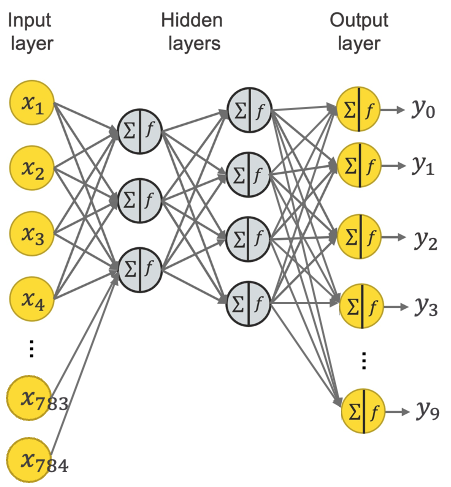



As shown above, the input layer has 784 neurons to fit in all pixels within each 2D image from MNIST, which has a 28x28 pixels.

The output layer has 10 neurons, corresponding to the label being 0, 1, 2, ..., 9. 

The goal is to have only one of the neurons being 1 and this neuron corresponds to the label of the image (i.e., the number of the handwirrent digit). All remain neurons should be 0.

In the middle, let's do only one hidden layer with 64 nodes. 

All neurons are fully connected.

We implement ReLU, sigmoid and softmax activation functions. SGD and Momentum optimizer are available.

Note, we use the softmax activation function in the output layer, since we wish to have probabilities of each class, so that we can measure how well our current forward pass performs.

## Useful packages

In [1]:
# Let's work within our working directory, e.g., where MNIST data is stored
import os
os.chdir('../../data/')

# We need numpy to handle data and array
import numpy as np

# We need matplotlib.pyplot to make plots
import matplotlib.pyplot as plt

# tensorflow and its keras API provides a NN framework
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, Model

# set hyperparameters at the beginning
l_rate = 0.1
Nepoch = 20
batch_size = 64

## Dataset preparation
MNIST contains 70,000 images of handwritten digits, in greyscale with pixel-values from 0 to 255. Let us first load the data. I have store them in two seperated numpy files.

In [2]:
# load data
images = np.load('./MNIST_images.npy', allow_pickle=True)
labels = np.load('./MNIST_labels.npy', allow_pickle=True)

# it is normally a good practice to rescale the training data into [0, 1] or [-1, 1]
images = (images - np.min(images)) / (np.max(images) - np.min(images))

# also a good practice to reshuffle the data set to get rid of any existing pattern
np.random.seed(1993) # fix your seeds for reproducibility!
shuffle_index = np.random.permutation(len(labels))
images = images[shuffle_index]
labels = labels[shuffle_index]

# flatten images into 1D array
x = images.reshape([len(labels), -1])
# create a one-hot encoding of the labels of size 10, i.e., #
# when label is 1, the array is [1, 0, 0, ..., 0]
# when label is 2, the array is [0, 1, 0, ..., 0]
# ...
# when label is 9, the array is [0, 0, 0, ..., 9]
y = np.array(labels.astype('int32')[:, None] == np.arange(10), dtype=np.float32)

### Let's divide the sample into training (90%) and test (10%) 

In [3]:
train_size = int(0.9 * len(x)) # tensorflow can split some from training set for validation
test_size = len(x) - train_size

x_train, x_test = x[:train_size], x[test_size:]
y_train, y_test = y[:train_size], y[test_size:]
images_test, labels_test = images[test_size:], labels[test_size:]

print("Training data: {} {}".format(x_train.shape, y_train.shape))
print("Test data: {} {}".format(x_test.shape, y_test.shape))

Training data: (63000, 784) (63000, 10)
Test data: (63000, 784) (63000, 10)


## Network definition

In [4]:
model = models.Sequential([
    layers.Input(shape=(28 * 28,)),                 # Input layer
    layers.Dense(128, activation='sigmoid'),        # First hidden layer
    layers.Dense(10, activation='softmax')          # Output layer
])

In [5]:
# Display the model's architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### let's visualize how the initial network behaves

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


Text(0, 0.5, 'Probability')

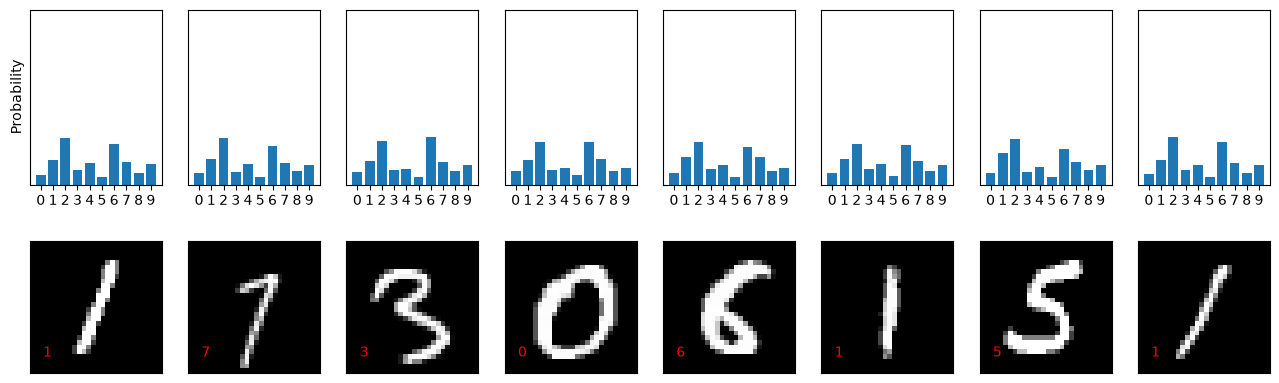

In [6]:
num_col = 8
fig, axes = plt.subplots(2, num_col, figsize=(num_col*2,5))
output = model.predict(x_test[:num_col])

for i in range(num_col):
    ax = axes[1,i]
    ax.imshow(images_test[i], cmap='gray')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.1,0.1, labels_test[i], va='bottom', ha='left', transform=ax.transAxes, color='r')
    axp = axes[0,i]
    axp.bar(np.arange(10), output[i])
    axp.set_xticks(np.arange(10))
    axp.set_yticks([])
    axp.set_ylim(0,0.8)
axes[0,0].set_ylabel('Probability')

<font color='red'>Also pretty bad!!!</font>


## Network training

In [7]:
# register the model
model.compile(
    optimizer=optimizers.Adam(learning_rate=l_rate),    # Optimizer
    loss='categorical_crossentropy',         # Loss function
)

In [8]:
# Train the model
history = model.fit(
    x_train, y_train,
    epochs=Nepoch,
    batch_size=batch_size,
    validation_split=0.2, 
)

Epoch 1/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5493 - val_loss: 0.4446
Epoch 2/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4205 - val_loss: 0.4187
Epoch 3/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3856 - val_loss: 0.4050
Epoch 4/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3829 - val_loss: 0.4307
Epoch 5/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3460 - val_loss: 0.3993
Epoch 6/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3313 - val_loss: 0.3799
Epoch 7/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3512 - val_loss: 0.3905
Epoch 8/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3394 - val_loss: 0.3479
Epoch 9/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3288 - val_loss: 0.3480
Epoch 10/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3250 - val_loss: 0.3538
Epoch 11/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3169 - val_loss: 0.3248
Epoch 12/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

### Let's view the loss

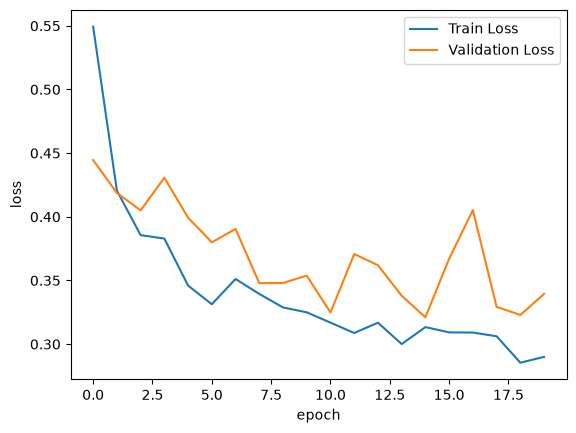

In [9]:
fig, ax = plt.subplots(1,1)
ax.plot(history.history['loss'], label='Train Loss')
ax.plot(history.history['val_loss'], label='Validation Loss')
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.legend(loc='upper right')

### how does the model prediction look now?

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


Text(0, 0.5, 'Probability')

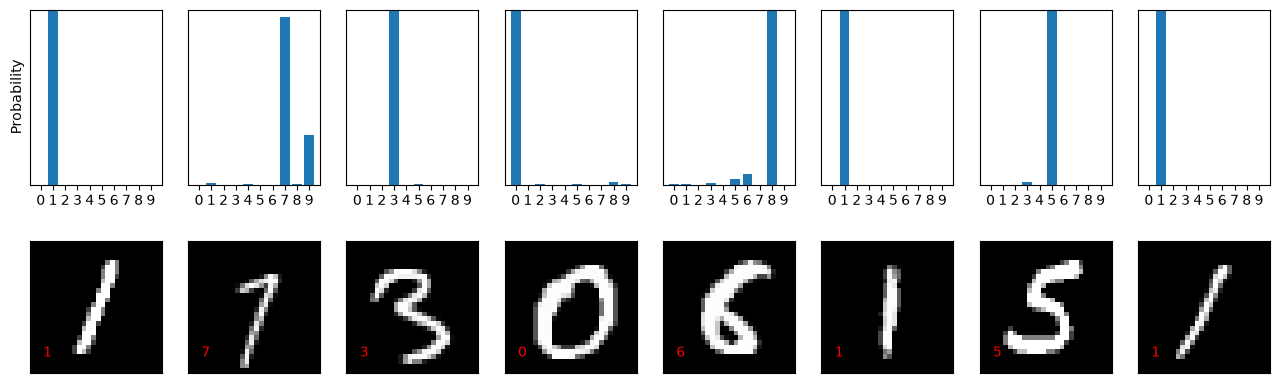

In [10]:
num_col = 8
fig, axes = plt.subplots(2, num_col, figsize=(num_col*2,5))
output = model.predict(x_test[:num_col])

for i in range(num_col):
    ax = axes[1,i]
    ax.imshow(images_test[i], cmap='gray')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.1,0.1, labels_test[i], va='bottom', ha='left', transform=ax.transAxes, color='r')
    axp = axes[0,i]
    axp.bar(np.arange(10), output[i])
    axp.set_xticks(np.arange(10))
    axp.set_yticks([])
    axp.set_ylim(0,0.8)
axes[0,0].set_ylabel('Probability')

<font color='red'>Pretty good, huh?</font> go back and try different learning rates, activation functions or even the architectures

## We can save the model onto disc and use it later 

In [11]:
# saving the entire model
model.save('model.keras') 
# loading
loaded_model = tf.keras.models.load_model('model.keras')

# saving only the architecture ( nno weights or optimizer state)
model_json = model.to_json()
with open("model_architecture.json", "w") as json_file:
    json_file.write(model_json)
# loading
with open('model_architecture.json', 'r') as json_file:
    loaded_model_json = json_file.read()
loaded_model = tf.keras.models.model_from_json(loaded_model_json)

# saving only the weights
model.save_weights('model.weights.h5')
# load the weights
model.load_weights('model.weights.h5')

## Let's talk about a couple of tricks

### Dropout
Dropout is a regularization technique that involves randomly "dropping out" (i.e., setting to zero) a fraction of the neurons in a neural network during each training iteration. By doing so, dropout prevents neurons from co-adapting too much to the training data, thereby reducing overfitting and enhancing the network's ability to generalize.



In [12]:
model = models.Sequential([
    layers.Input(shape=(28 * 28,)),              # Input layer
    layers.Dense(512, activation='relu'),        # First hidden layer
    layers.Dropout(0.2),                         # Dropout for regularization
    layers.Dense(256, activation='relu'),        # Second hidden layer
    layers.Dropout(0.2),                         # Dropout for regularization
    layers.Dense(10, activation='softmax')  # Output layer
])

### EarlyStopping
Early Stopping is a form of regularization used to avoid overfitting when training machine learning models. It involves monitoring the model's performance on a separate validation dataset during the training process and stopping the training once the performance on the validation set ceases to improve for a specified number of consecutive epochs.


In [13]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', # Quantity to be monitored.
    patience=5, # Number of epochs with no improvement after which trainning is stopped.
)

### ModelCheckpoint
ModelCheckpoint is a callback function in TensorFlow Keras that allows you to save the state of your model at various stages during training. It can save the entire model (architecture, weights, and optimizer state) or just the model's weights. 

In [14]:
checkpoint = callbacks.ModelCheckpoint(
    'best_mnist_dense_model.keras', # path to save the model file
    monitor='val_loss',  # Quantity to be monitored.
    save_best_only=True, # If True, only saves when the monitored metric improves.
    save_weights_only = False, # If True, only the model's weights are saved; otherwise, the entire model is saved.
)

### ReduceLROnPlateau
ReduceLROnPlateau is a callback function that monitors a specified metric during training and reduces the learning rate by a predefined factor when the metric has ceased to improve for a set number of epochs (patience). This adaptive adjustment helps the model converge more smoothly and avoid getting stuck in local minima, enhancing overall training efficiency and performance.

In [15]:
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss', # Quantity to be monitored.
    factor=0.2, # Factor by which the learning rate will be reduced.
    patience=10, # Number of epochs with no improvement after which learning rate will be reduced.	
    min_lr=1e-6 # Lower bound on the learning rate.
)

In [16]:
model.compile(
    optimizer='adam',    # Optimizer
    loss='categorical_crossentropy',         # Loss function
)
history = model.fit(
    x_train, y_train,
    epochs=1000,
    batch_size=batch_size,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=False
)

### how does the model prediction look now?

(0.0, 1.0)

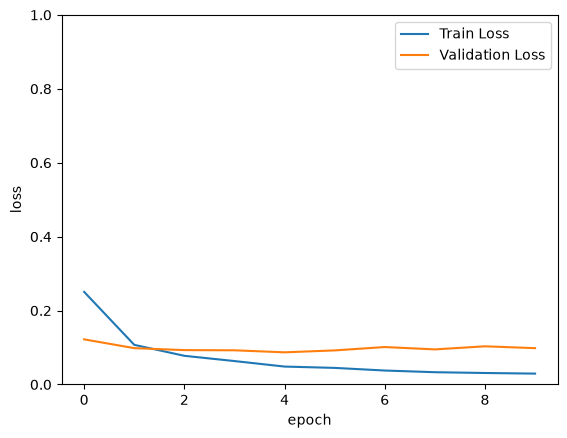

In [17]:
fig, ax = plt.subplots(1,1)
ax.plot(history.history['loss'], label='Train Loss')
ax.plot(history.history['val_loss'], label='Validation Loss')
ax.set_xlabel('epoch')
ax.set_ylabel('loss')
ax.legend(loc='upper right')
ax.set_ylim(0,1)

## Demo: multiple CPUs for data loading, and a GPU for training

These two patterns are independent: `PyDataset` below controls how batches are *prepared* (e.g. decoding/augmenting data) before they reach the model, while `tf.device`/`tf.distribute.MirroredStrategy` control which hardware actually runs the matrix multiplications.

### Using multiple CPUs for data loading with `keras.utils.PyDataset`

As noted earlier, `workers`/`use_multiprocessing`/`max_queue_size` now live on a `PyDataset` subclass rather than on `fit()` directly. Below we simulate an expensive per-batch step (e.g. reading/augmenting images from disk) with `time.sleep`, then compare a single worker against 4 threaded workers on a subset of the training data.

In [18]:
import time

class SlowMNISTDataset(tf.keras.utils.PyDataset):
    """Pretends each batch needs some expensive preprocessing."""
    def __init__(self, x, y, batch_size, **kwargs):
        super().__init__(**kwargs)  # workers / use_multiprocessing / max_queue_size go here
        self.x, self.y, self.batch_size = x, y, batch_size

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def __getitem__(self, idx):
        low = idx * self.batch_size
        high = min(low + self.batch_size, len(self.x))
        time.sleep(0.02)  # stand-in for a costly preprocessing/augmentation step
        return self.x[low:high], self.y[low:high]

def build_small_model():
    m = models.Sequential([
        layers.Input(shape=(28 * 28,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy')
    return m

def time_fit(workers, use_multiprocessing, x, y):
    model = build_small_model()
    ds = SlowMNISTDataset(x, y, batch_size, workers=workers, use_multiprocessing=use_multiprocessing)
    t0 = time.time()
    model.fit(ds, epochs=1, verbose=0)
    return time.time() - t0

# use a small subset so the demo runs quickly
x_small, y_small = x_train[:3000], y_train[:3000]

t_serial = time_fit(workers=1, use_multiprocessing=False, x=x_small, y=y_small)
t_threads = time_fit(workers=4, use_multiprocessing=False, x=x_small, y=y_small)
print(f"1 worker (serial):   {t_serial:.2f} s")
print(f"4 workers (threads): {t_threads:.2f} s")

1 worker (serial):   1.51 s
4 workers (threads): 0.79 s


### Training on a GPU (with a graceful CPU fallback)

If this machine doesn't have a GPU attached, the cell below detects that and falls back to `/CPU:0` — the same code runs on `/GPU:0` unmodified on a CUDA- or Metal-enabled machine.

In [19]:
gpus = tf.config.list_physical_devices('GPU')
print(f"Found {len(gpus)} GPU(s): {gpus}")
device = '/GPU:0' if gpus else '/CPU:0'
print(f"Training on {device}")

with tf.device(device):
    gpu_model = build_small_model()
    history = gpu_model.fit(
        x_train, y_train,
        epochs=2,
        batch_size=batch_size,
        validation_split=0.2,
        verbose=0,
    )
print("Final training loss:", history.history['loss'][-1])

Found 0 GPU(s): []
Training on /CPU:0
Final training loss: 0.17865745723247528
